In [1]:
### TODO:
### - simplify functions
### - add feature to only search rotation in one dimension

In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import affine_transform

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

	 original


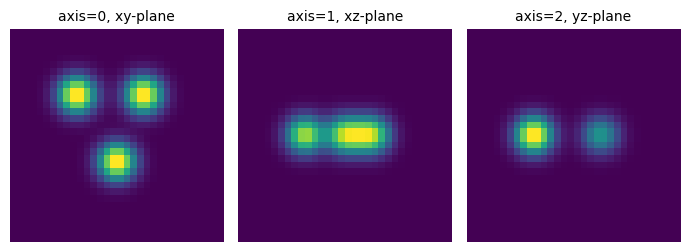

	 rotated


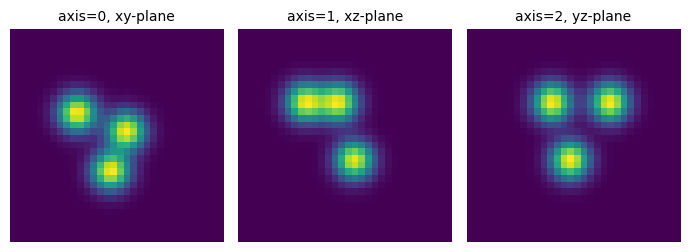

In [4]:
L = 32
sigma = 2

omega = -np.deg2rad(90)
theta = -np.deg2rad(60)
phi = -np.deg2rad(30)

F = utils.generate_3d_triangle_gaussian_shape(L, sigma)
G = transforms.rotate_voxel_zyz(F, omega, theta, phi, order=1)

F = signals.Signal(F, d=3).preprocess_signals()[0]
G = signals.Signal(G, d=3).preprocess_signals()[0]

print('\t original')
plots.orthogonal_2D_projection_plot(F)
print('\t rotated')
plots.orthogonal_2D_projection_plot(G)

In [5]:
n_omega, n_theta, n_phi = 12, 12, 12

omegas = np.linspace(0, 2*np.pi, n_omega, endpoint=False)
thetas = np.linspace(0, np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

dists = np.zeros((n_omega, n_theta, n_phi))

t = time.time()

for a_idx, a in enumerate(omegas):
    for b_idx, b in enumerate(thetas):
        for c_idx, c in enumerate(phis):
        
            G_r = rotate_voxel_zyz(G, a, b, c, order=1)
            dists[a_idx, b_idx, c_idx] = np.linalg.norm(F - G_r)

print('rotational distance time :', time.time() - t)

rotational distance time : 3.916395425796509


In [6]:
# dists = dists / np.amax(dists)
# plt.plot(np.rad2deg(thetas), dists_theta)
# plt.ylim(-0.1, 1.1)
# plt.show()

In [7]:
np.rad2deg(omegas)

array([  0.,  30.,  60.,  90., 120., 150., 180., 210., 240., 270., 300.,
       330.])

In [8]:
min_omega_idx, min_theta_idx, min_phi_idx = np.unravel_index(np.argmin(dists, axis=None), dists.shape)

min_omega = omegas[min_omega_idx]
min_theta = thetas[min_theta_idx]
min_phi = phis[min_phi_idx]

print('gt_omega: ', np.round(np.rad2deg(-omega)))
print('gt_theta: ', np.round(np.rad2deg(-theta)))
print('  gt_phi: ', np.round(np.rad2deg(-phi)))
print('\n\n')
print('min_omega: ', np.round(np.rad2deg(min_omega), 2))
print('min_theta: ', np.round(np.rad2deg(min_theta), 2))
print('  min_phi: ', np.round(np.rad2deg(min_phi), 2))

gt_omega:  90.0
gt_theta:  60.0
  gt_phi:  30.0



min_omega:  30.0
min_theta:  60.0
  min_phi:  90.0


In [9]:
### Add undo rotation and visualization here
### add test to see if rotations are approximately equivalent
### - norm between rotation matrix?
### - how to get rotation angles to match conventions

In [10]:
R_gt = transforms.rotate_z(omega) @ transforms.rotate_y(theta) @ transforms.rotate_z(phi)

R_est = transforms.rotate_z(-min_phi) @ transforms.rotate_y(-min_theta) @ transforms.rotate_z(-min_omega) 

In [11]:
np.allclose(R_gt, R_est), np.linalg.norm(R_gt - R_est)

(True, np.float64(0.0))